# 3. Character detection

DASS ONNX: letterbox RGB to 1024 square with padding 114, keep raw 0–255 float values, and apply NMS separately to faces and bodies. Outputs are already decoded cx, cy, width, height, score. Pair a face with the body containing most of it; unmatched faces become separate characters. This is a geometric heuristic to inspect visually.

Reference: https://huggingface.co/comicbox/comicapp-char-detector

Run cells top to bottom, then inspect the displayed output before continuing.


In [1]:
from pathlib import Path
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Works when the kernel starts in the project root or this stage folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "models.json").exists():
    raise FileNotFoundError("Start the kernel in 1pageTest or a stage folder.")
SEQUENCE_ID = "seq_71033fec4de494fc"
PAGE_NUMBER = 1
# Dataset page filenames are zero-padded: page 1 is 01.png.
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
OUT = ROOT / "data/intermediate"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = json.loads((ROOT / "models.json").read_text(encoding="utf-8"))
if not PAGE.is_file():
    raise FileNotFoundError(f"Put your manga page at {PAGE}, or edit PAGE.")
page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def save_stage(name, records):
    path = OUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records},
                               ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved {path}")

def load_stage(name):
    path = OUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the preceding stage first.")
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to a different page. Rerun the earlier stages.")
    return payload["records"]


In [2]:
import math
import numpy as np
import onnxruntime as ort

MODEL = Path(MODELS["character_detection"]["local_path"])
CONFIDENCE = 0.35
NMS_IOU = 0.45
if not MODEL.is_file():
    raise FileNotFoundError(f"Download the DASS detector to {MODEL}; see README.md.")
available = ort.get_available_providers()
providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in available]
session = ort.InferenceSession(str(MODEL), providers=providers)
size = 1024
scale = min(size / page.width, size / page.height)
rw, rh = max(1, round(page.width * scale)), max(1, round(page.height * scale))
left, top = (size - rw) // 2, (size - rh) // 2
canvas = Image.new("RGB", (size, size), (114, 114, 114))
canvas.paste(page.resize((rw, rh), Image.Resampling.BILINEAR), (left, top))
tensor = np.asarray(canvas, dtype=np.float32).transpose(2, 0, 1)[None]
faces_raw, bodies_raw = session.run(None, {session.get_inputs()[0].name: tensor})
print("Providers:", session.get_providers())
print("Faces:", faces_raw.shape, "Bodies:", bodies_raw.shape)


Providers: ['CPUExecutionProvider']
Faces: (1, 21504, 5) Bodies: (1, 21504, 5)


In [3]:
def decode_head(raw):
    rows = np.asarray(raw)[0]
    if rows.ndim != 2 or rows.shape[1] != 5:
        raise ValueError(f"Expected [1, N, 5] detections; got {raw.shape}")
    rows = rows[np.isfinite(rows).all(axis=1) & (rows[:, 4] >= CONFIDENCE)]
    boxes = np.column_stack((rows[:, 0] - rows[:, 2] / 2, rows[:, 1] - rows[:, 3] / 2,
                             rows[:, 0] + rows[:, 2] / 2, rows[:, 1] + rows[:, 3] / 2))
    order = np.argsort(-rows[:, 4], kind="stable")
    keep = []
    while len(order):
        index = int(order[0])
        keep.append(index)
        rest = order[1:]
        intersection = np.maximum(0, np.minimum(boxes[index, 2:], boxes[rest, 2:]) -
                                   np.maximum(boxes[index, :2], boxes[rest, :2])).prod(axis=1)
        area = np.maximum(0, boxes[:, 2:] - boxes[:, :2]).prod(axis=1)
        iou = intersection / np.maximum(area[index] + area[rest] - intersection, 1e-6)
        order = rest[iou <= NMS_IOU]
    detections = []
    for index in keep:
        box = boxes[index].copy()
        box[[0, 2]] = (box[[0, 2]] - left) / (rw / page.width)
        box[[1, 3]] = (box[[1, 3]] - top) / (rh / page.height)
        x1, y1, x2, y2 = box
        box = [max(0, math.floor(x1)), max(0, math.floor(y1)),
               min(page.width, math.ceil(x2)), min(page.height, math.ceil(y2))]
        if box[2] > box[0] and box[3] > box[1]:
            detections.append({"box": box, "confidence": float(rows[index, 4])})
    return detections

faces, bodies = decode_head(faces_raw), decode_head(bodies_raw)
save_stage("faces.json", faces)
save_stage("bodies.json", bodies)

def face_coverage(face, body):
    f, b = face["box"], body["box"]
    intersection = max(0, min(f[2], b[2]) - max(f[0], b[0])) * max(0, min(f[3], b[3]) - max(f[1], b[1]))
    return intersection / ((f[2] - f[0]) * (f[3] - f[1]))

characters = [{"box": body["box"], "body": body, "face": None} for body in bodies]
candidates = sorted(((face_coverage(face, body), fi, bi)
                     for fi, face in enumerate(faces) for bi, body in enumerate(bodies)), reverse=True)
used_faces, used_bodies = set(), set()
for coverage, fi, bi in candidates:
    if coverage >= 0.8 and fi not in used_faces and bi not in used_bodies:
        characters[bi]["face"] = faces[fi]
        used_faces.add(fi)
        used_bodies.add(bi)
for fi, face in enumerate(faces):
    if fi not in used_faces:
        characters.append({"box": face["box"], "face": face, "body": None})
characters.sort(key=lambda c: (c["box"][1], -c["box"][0]))
for i, character in enumerate(characters, 1):
    character["character_id"] = f"C{i}"
save_stage("characters.json", characters)


Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\faces.json
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\bodies.json
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\characters.json


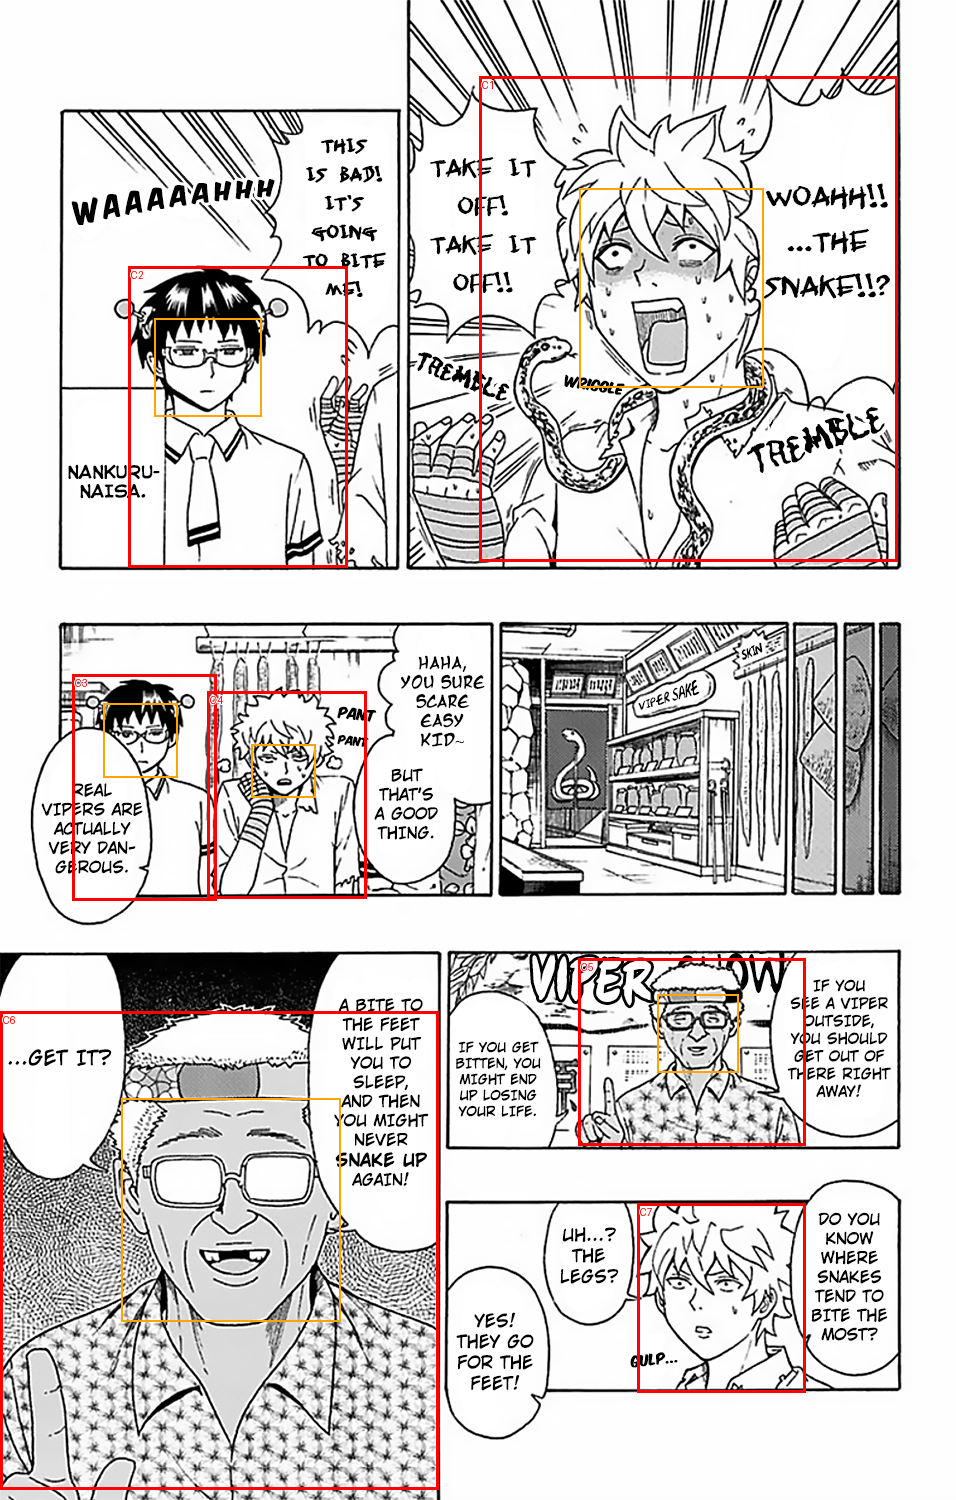

6 faces, 7 bodies, 7 character instances


In [4]:
preview = page.copy()
draw = ImageDraw.Draw(preview)
for character in characters:
    x1, y1, x2, y2 = character["box"]
    draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
    draw.text((x1 + 3, y1 + 3), character["character_id"], fill="red", stroke_width=1, stroke_fill="white")
    if character["face"] is not None:
        draw.rectangle(character["face"]["box"], outline="orange", width=2)
preview.save(OUT / "character_preview.png")
display(preview)
print(f"{len(faces)} faces, {len(bodies)} bodies, {len(characters)} character instances")
